# Eclipse Analytics | NBA Shot Data Preparation & EDA
**Source:** [shufinskiy/nba_data](https://github.com/shufinskiy/nba_data), `shotdetail_2025.csv` (2025–26 regular season).  
**Goal:** Investigate factors associated with shot success and prepare data for Logistic Regression, Random Forest, and XGBoost.  
**Instructions:** Put `shotdetail_2025 (1).tar.xz` in the same folder as this notebook, then run all cells. The notebook extracts the CSV *in memory*. No model is trained here.

## 1. Load libraries and raw data

In [1]:
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

archive = Path('shotdetail_2025 (1).tar.xz')
with tarfile.open(archive, 'r:xz') as tar:
    with tar.extractfile('shotdetail_2025.csv') as f:
        raw = pd.read_csv(f)
print('Shape:', raw.shape)
display(raw.head())

Shape: (219160, 24)


,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM
0,Shot Chart Detail,22500014,7,1629638,Nickeil Alexander-Walker,1610612737,Atlanta Hawks,1,11,43,...,Right Side Center(RC),24+ ft.,26,175,202,1,0,20260119,ATL,MIL
1,Shot Chart Detail,22500014,10,1630700,Dyson Daniels,1610612737,Atlanta Hawks,1,11,27,...,Center(C),Less Than 8 ft.,1,-4,12,1,1,20260119,ATL,MIL
2,Shot Chart Detail,22500014,13,1630700,Dyson Daniels,1610612737,Atlanta Hawks,1,10,59,...,Right Side(R),24+ ft.,24,238,71,1,0,20260119,ATL,MIL
3,Shot Chart Detail,22500014,17,1629638,Nickeil Alexander-Walker,1610612737,Atlanta Hawks,1,10,25,...,Center(C),Less Than 8 ft.,2,-10,22,1,1,20260119,ATL,MIL
4,Shot Chart Detail,22500014,21,1630552,Jalen Johnson,1610612737,Atlanta Hawks,1,9,59,...,Center(C),Less Than 8 ft.,1,7,12,1,1,20260119,ATL,MIL


## 2. Data quality audit
Check missing values, duplicates, identifier uniqueness, outcome balance, and field ranges. We *do not* automatically drop rows based on outliers: long heaves can be legitimate NBA shots.

In [2]:
print('Missing values per column:')
display(raw.isna().sum().to_frame('missing').T)
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate (GAME_ID, GAME_EVENT_ID):', raw.duplicated(['GAME_ID','GAME_EVENT_ID']).sum())
print('Outcome distribution:')
display(raw['SHOT_MADE_FLAG'].value_counts(dropna=False))
print('Min and max shot distance:', raw['SHOT_DISTANCE'].min(), raw['SHOT_DISTANCE'].max())
print('Seasons covered:', raw.GAME_DATE.min(), raw.GAME_DATE.max())

Missing values per column:


,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_AREA,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Exact duplicate rows: 0
Duplicate (GAME_ID, GAME_EVENT_ID): 0
Outcome distribution:


SHOT_MADE_FLAG
0    115933
1    103227
Name: count, dtype: int64

Min and max shot distance: 0 73
Seasons covered: 20251021 20260412


## 3. Clean and engineer features
Convert dates, construct time remaining in period, three-point and overtime indicators, and distance groups. Validate clocks using 12-minute regulation and 5-minute overtime periods. Remove invalid rows or repeated event IDs if found, but retain legitimate long-distance shots.

In [3]:
df = raw.copy()
df['GAME_DATE'] = pd.to_datetime(df['GAME_DATE'].astype(str), format='%Y%m%d', errors='coerce')
df['TIME_REMAINING_SECONDS'] = df['MINUTES_REMAINING'] * 60 + df['SECONDS_REMAINING']
df['IS_THREE'] = (df['SHOT_TYPE'] == '3PT Field Goal').astype(int)
df['IS_OVERTIME'] = (df['PERIOD'] > 4).astype(int)
df['SHOT_DISTANCE_GROUP'] = pd.cut(df['SHOT_DISTANCE'], bins=[-1,3,10,16,23,100], labels=['0–3 ft','4–10 ft','11–16 ft','17–23 ft','24+ ft'])

valid = (
    df['SHOT_MADE_FLAG'].isin([0, 1])
    & df['SHOT_ATTEMPTED_FLAG'].eq(1)
    & df['SHOT_DISTANCE'].ge(0)
    & df['SECONDS_REMAINING'].between(0, 59)
    & df['PERIOD'].between(1, 10)
    & df['MINUTES_REMAINING'].ge(0)
    & df['GAME_DATE'].notna()
    & (df['TIME_REMAINING_SECONDS'] <= np.where(df['PERIOD'] <= 4, 720, 300))
)
not_duplicate = ~df.duplicated(['GAME_ID', 'GAME_EVENT_ID'])
clean = df.loc[valid & not_duplicate].copy()
print(f'Original: {len(raw):,}; cleaned: {len(clean):,}; excluded: {len(raw)-len(clean):,}')
print('Date range:', clean['GAME_DATE'].min().date(), 'to', clean['GAME_DATE'].max().date())
print('Shot attempts:', len(clean), '| games:', clean.GAME_ID.nunique(), '| players:', clean.PLAYER_ID.nunique())

Original: 219,160; cleaned: 219,160; excluded: 0
Date range: 2025-10-21 to 2026-04-12
Shot attempts: 219160 | games: 1230 | players: 582


## 4. Exploratory Data Analysis (EDA)

Overall field-goal percentage: 47.1 %


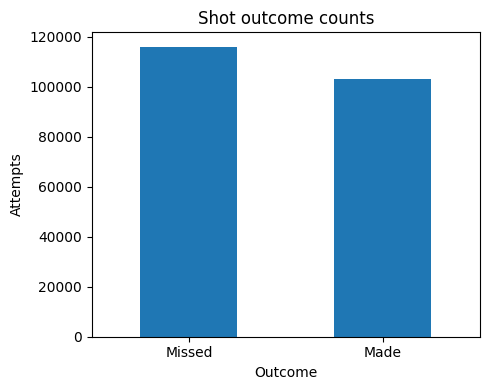

In [4]:
print('Overall field-goal percentage:', round(100*clean.SHOT_MADE_FLAG.mean(),2),'%')
fig, ax = plt.subplots(figsize=(5,4))
clean.SHOT_MADE_FLAG.value_counts().sort_index().rename(index={0:'Missed',1:'Made'}).plot.bar(ax=ax)
ax.set(title='Shot outcome counts',ylabel='Attempts',xlabel='Outcome');plt.xticks(rotation=0);plt.tight_layout();plt.show()

### EDA A — Shooting accuracy by distance

,FG percentage (fraction),Attempts
SHOT_DISTANCE_GROUP,,
0–3 ft,0.670940,62253
4–10 ft,0.440332,38421
11–16 ft,0.446362,19184
17–23 ft,0.389338,28325
24+ ft,0.351522,70977


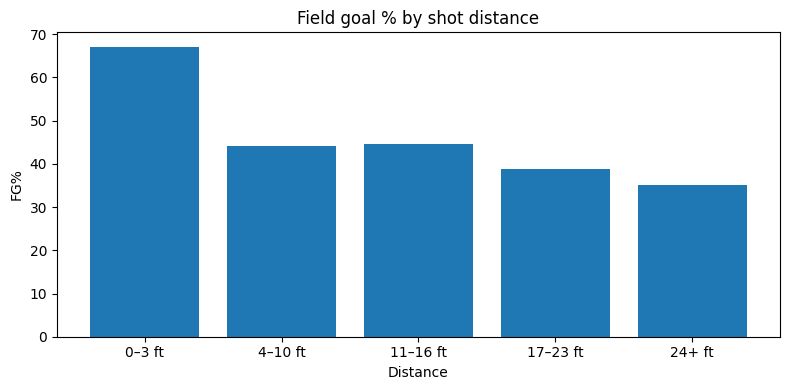

In [14]:
dist = clean.groupby('SHOT_DISTANCE_GROUP', observed=True)['SHOT_MADE_FLAG'].agg(['mean','size'])
display(dist.rename(columns={'mean':'FG percentage (fraction)','size':'Attempts'}))
fig, ax=plt.subplots(figsize=(8,4))
ax.bar(dist.index.astype(str),100*dist['mean'])
ax.set(title='Field goal % by shot distance',xlabel='Distance',ylabel='FG%');plt.tight_layout();plt.show()

In [16]:
### Key Finding: Shot Distance and Shooting Accuracy

Our analysis shows a clear relationship between shot distance and shooting accuracy. Shots taken closer to the basket generally have higher success rates than attempts from beyond the three-point line.

This suggests that shot distance will likely be an important feature when predicting whether a player makes a shot. However, distance alone cannot explain every shot outcome, since factors such as defensive pressure, player ability, and shot selection may also influence shooting percentage.

SyntaxError: invalid syntax (2201136114.py, line 3)

### EDA B — 2-pointers versus 3-pointers

,FG percentage (fraction),Attempts
SHOT_TYPE,,
2PT Field Goal,0.550043,128190
3PT Field Goal,0.359646,90970


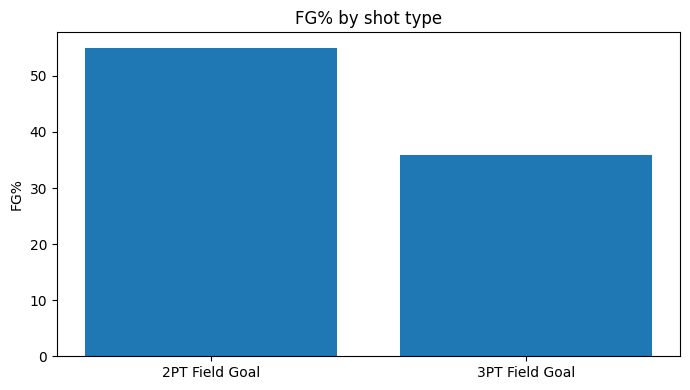

In [6]:
types=clean.groupby('SHOT_TYPE')['SHOT_MADE_FLAG'].agg(['mean','size'])
display(types.rename(columns={'mean':'FG percentage (fraction)','size':'Attempts'}))
fig,ax=plt.subplots(figsize=(7,4));ax.bar(types.index,100*types['mean']);ax.set(title='FG% by shot type',ylabel='FG%');plt.tight_layout();plt.show()

### EDA C — Quarter / overtime
Overtime results have smaller sample sizes, so avoid over-interpreting differences.

,mean,size
PERIOD,,
1,0.474843,56842
2,0.469337,54854
3,0.477648,54379
4,0.462759,51999
5,0.420168,952
6,0.402985,134


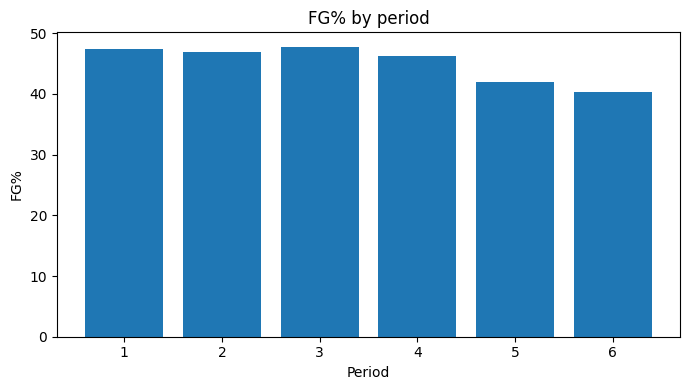

In [7]:
q=clean.groupby('PERIOD')['SHOT_MADE_FLAG'].agg(['mean','size'])
display(q)
fig,ax=plt.subplots(figsize=(7,4));ax.bar(q.index.astype(str),100*q['mean']);ax.set(title='FG% by period',xlabel='Period',ylabel='FG%');plt.tight_layout();plt.show()

### EDA D — Shot location
Court location uses source coordinates; this is a density view, not a calibrated court diagram.

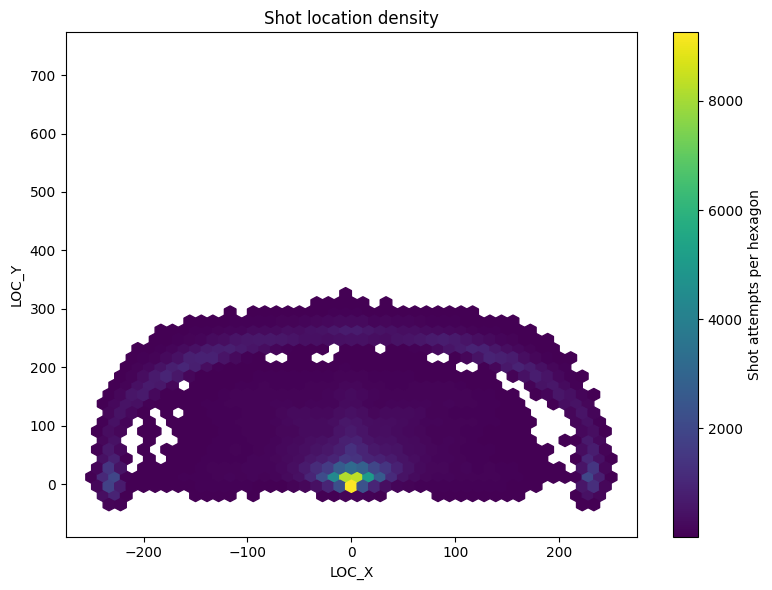

In [8]:
fig,ax=plt.subplots(figsize=(8,6))
h=ax.hexbin(clean.LOC_X,clean.LOC_Y,gridsize=45,mincnt=15,cmap='viridis')
fig.colorbar(h,ax=ax,label='Shot attempts per hexagon')
ax.set(title='Shot location density',xlabel='LOC_X',ylabel='LOC_Y');plt.tight_layout();plt.show()

### EDA E — Shot success by location
Each hexagon is colored by make rate. Only show regions with at least 30 attempts to avoid noisy percentages.

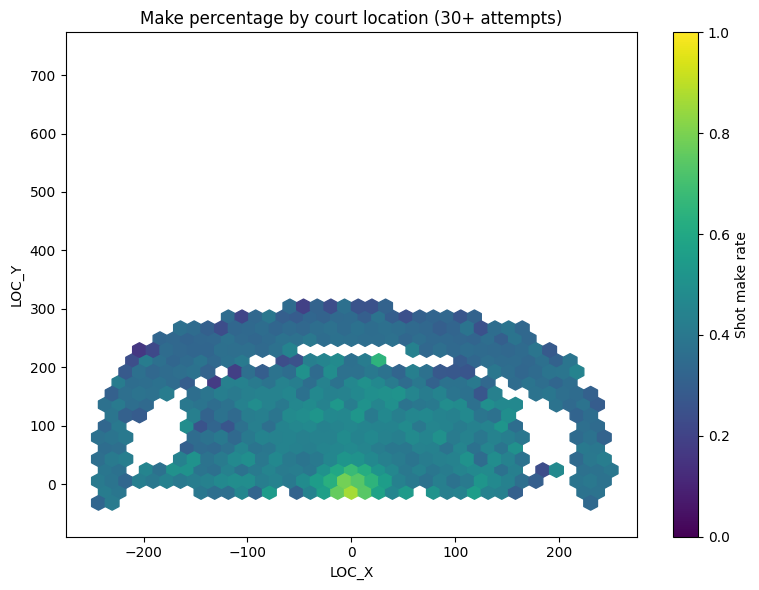

In [9]:
fig,ax=plt.subplots(figsize=(8,6))
h=ax.hexbin(clean.LOC_X,clean.LOC_Y,C=clean.SHOT_MADE_FLAG,reduce_C_function=np.mean,gridsize=38,mincnt=30,cmap='viridis',vmin=0,vmax=1)
fig.colorbar(h,ax=ax,label='Shot make rate')
ax.set(title='Make percentage by court location (30+ attempts)',xlabel='LOC_X',ylabel='LOC_Y');plt.tight_layout();plt.show()

### EDA F — Players with enough attempts
Rank only players with at least 200 attempts in the dataset. Raw FG% does not adjust for shot difficulty.

In [10]:
players=clean.groupby('PLAYER_NAME')['SHOT_MADE_FLAG'].agg(['mean','size']).query('size >= 200').sort_values('mean',ascending=False)
display(players.head(15).rename(columns={'mean':'FG percentage (fraction)','size':'Attempts'}))

,FG percentage (fraction),Attempts
PLAYER_NAME,,
Jaxson Hayes,0.755725,262
Ryan Kalkbrenner,0.752577,291
Mitchell Robinson,0.723301,206
Robert Williams III,0.708000,250
Jakob Poeltl,0.700000,310
Rudy Gobert,0.682281,491
Goga Bitadze,0.675556,225
Deandre Ayton,0.670549,601
Daniel Gafford,0.655063,316


## 5. Prepare modeling columns and guard against leakage
`SHOT_MADE_FLAG` is the **target**. `EVENT_TYPE` literally contains Made/Missed and must never be included as a predictor. `SHOT_ATTEMPTED_FLAG` and `GRID_TYPE` are constant. `GAME_EVENT_ID` is an identifier, not a meaningful shot feature. `ACTION_TYPE` describes the shot attempt but may not be known before the shot, so only use it if the prediction task explicitly permits shot-action information. For evaluation, split by game (or chronologically) rather than randomly splitting shots within the same game.

In [11]:
target='SHOT_MADE_FLAG'
numeric_features=['SHOT_DISTANCE','LOC_X','LOC_Y','PERIOD','TIME_REMAINING_SECONDS','IS_THREE','IS_OVERTIME']
category_features=['SHOT_ZONE_BASIC']  # optional; derived from location and redundant with coordinates
model_candidate=clean[numeric_features+[target,'GAME_ID','GAME_DATE']].copy()
print('Numeric modeling columns:',numeric_features)
print('Target:',target)
print('Model candidate shape:',model_candidate.shape)
display(model_candidate.head())

Numeric modeling columns: ['SHOT_DISTANCE', 'LOC_X', 'LOC_Y', 'PERIOD', 'TIME_REMAINING_SECONDS', 'IS_THREE', 'IS_OVERTIME']
Target: SHOT_MADE_FLAG
Model candidate shape: (219160, 10)


,SHOT_DISTANCE,LOC_X,LOC_Y,PERIOD,TIME_REMAINING_SECONDS,IS_THREE,IS_OVERTIME,SHOT_MADE_FLAG,GAME_ID,GAME_DATE
0,26,175,202,1,703,1,0,0,22500014,2026-01-19
1,1,-4,12,1,687,0,0,1,22500014,2026-01-19
2,24,238,71,1,659,1,0,0,22500014,2026-01-19
3,2,-10,22,1,625,0,0,1,22500014,2026-01-19
4,1,7,12,1,599,0,0,1,22500014,2026-01-19


## 6. Export cleaned data and modeling candidates
The full cleaned CSV retains the original descriptive columns for future EDA. The modeling candidate CSV only includes potential pre-shot features, the target, and game/date identifiers for grouped splitting. **No model has been fit.**

In [12]:
clean.to_csv('nba_shots_2025_26_prepared.csv',index=False)
model_candidate.to_csv('nba_shots_2025_26_model_candidates.csv',index=False)
print('Saved both CSV files.')

Saved both CSV files.


## 7. Discussion points for the team
- Are shot location and distance sufficient, or should we include player identity (carefully encoded)?
- Should we predict a *probability* and judge it with log loss/Brier score, rather than only classification accuracy?
- Are we predicting before a shot is taken? If yes, avoid any feature known only after the attempt.
- Shot-zone labels largely repeat information in shot coordinates; compare with/without them.
- Train/test split should hold out games or later dates to reduce overly optimistic performance.
- Association in EDA is not causation; lower three-point FG% does not by itself mean worse scoring value.